# Morphological Operations

Morphology cleans binary images using a small structuring element (kernel). Erosion shrinks white regions, dilation grows them, and their combinations - opening and closing - remove specks and fill holes. Almost every real detection pipeline includes this step between thresholding and measurement.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Erosion and dilation

Erosion keeps a white pixel only if the whole kernel fits in white - it shrinks objects and deletes thin parts and specks. Dilation keeps a pixel white if any part of the kernel touches white - it grows objects and joins near parts. `iterations` repeats the operation.

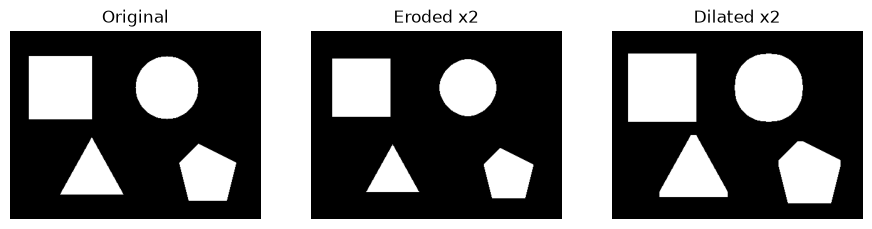

In [2]:
img = cv2.imread("../assets/contours_shapes.png", cv2.IMREAD_GRAYSCALE)
_, binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((5, 5), np.uint8)
eroded = cv2.erode(binary, kernel, iterations=2)
dilated = cv2.dilate(binary, kernel, iterations=2)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, m, name in zip(axes, (binary, eroded, dilated), ("Original", "Eroded x2", "Dilated x2")):
    ax.imshow(m, cmap="gray"); ax.set_title(name); ax.axis("off")
plt.show()

## Opening and closing

Opening = erosion then dilation: removes white specks smaller than the kernel without shrinking the real objects much. Closing = dilation then erosion: fills black holes inside objects. `cv2.morphologyEx` applies both in one call.

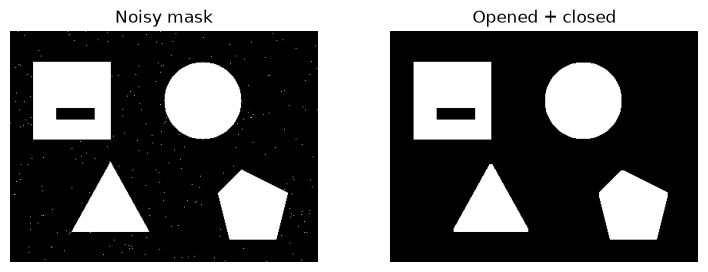

In [3]:
noisy_mask = binary.copy()
rng = np.random.default_rng(5)
ys, xs = rng.integers(0, noisy_mask.shape[0], 300), rng.integers(0, noisy_mask.shape[1], 300)
noisy_mask[ys, xs] = 255                       # white specks on background
noisy_mask[100:115, 60:110] = 0                # a black hole inside a shape
kernel = np.ones((5, 5), np.uint8)
opened = cv2.morphologyEx(noisy_mask, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(noisy_mask, cmap="gray"); axes[0].set_title("Noisy mask")
axes[1].imshow(closed, cmap="gray"); axes[1].set_title("Opened + closed")
for ax in axes: ax.axis("off")
plt.show()

## Gradient, top-hat and black-hat

The morphological gradient (dilation minus erosion) outlines objects. Top-hat (original minus opening) extracts bright details smaller than the kernel; black-hat extracts dark details. These are used for licence-plate and defect detection.

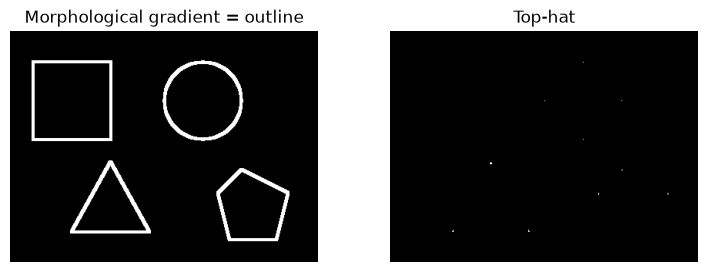

In [4]:
gradient = cv2.morphologyEx(binary, cv2.MORPH_GRADIENT, kernel)
tophat = cv2.morphologyEx(binary, cv2.MORPH_TOPHAT, kernel)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(gradient, cmap="gray"); axes[0].set_title("Morphological gradient = outline")
axes[1].imshow(tophat, cmap="gray"); axes[1].set_title("Top-hat")
for ax in axes: ax.axis("off")
plt.show()

## Choosing the kernel: shape and size

Kernels can be rectangular, elliptical or cross-shaped via `cv2.getStructuringElement`. The kernel must be smaller than the noise you want to remove but smaller than the objects you want to keep - that trade-off is the whole skill of this step.

In [5]:
for shape, name in [(cv2.MORPH_RECT, "RECT"), (cv2.MORPH_ELLIPSE, "ELLIPSE"), (cv2.MORPH_CROSS, "CROSS")]:
    k = cv2.getStructuringElement(shape, (7, 7))
    print(name, "kernel sum:", int(k.sum()))
rect_k = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 3))
print("Wide 9x3 kernel (good for horizontal text lines):\n", rect_k)

RECT kernel sum: 49
ELLIPSE kernel sum: 33
CROSS kernel sum: 13
Wide 9x3 kernel (good for horizontal text lines):
 [[1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1]]


## Extracting horizontal and vertical lines

A wide thin kernel keeps only horizontal structures; a tall thin kernel keeps only vertical ones. Opening with each is a classic document-analysis trick for finding table lines and staff lines.

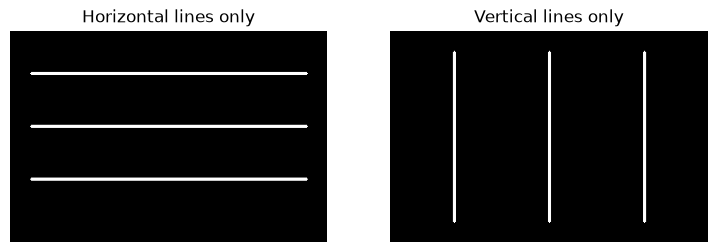

In [6]:
page = np.full((200, 300), 255, np.uint8)
for y in (40, 90, 140):
    cv2.line(page, (20, y), (280, y), 0, 2)
for x in (60, 150, 240):
    cv2.line(page, (x, 20), (x, 180), 0, 2)
_, bw = cv2.threshold(page, 200, 255, cv2.THRESH_BINARY_INV)
horizontal = cv2.morphologyEx(bw, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (25, 1)))
vertical = cv2.morphologyEx(bw, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, 25)))
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(horizontal, cmap="gray"); axes[0].set_title("Horizontal lines only")
axes[1].imshow(vertical, cmap="gray"); axes[1].set_title("Vertical lines only")
for ax in axes: ax.axis("off")
plt.show()

## Full cleaning pipeline on a colour-detection mask

Putting it together: HSV mask (notebook 04) -> opening to delete specks -> closing to fill the object -> the cleaned mask feeds measurement. This exact sequence appears in the colour-tracker project in notebook 17.

Speck removed, green pixels: 22146


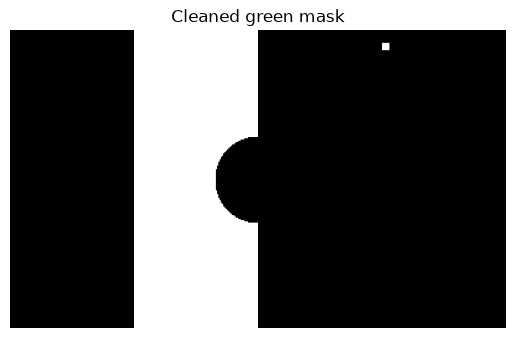

In [7]:
blocks = cv2.imread("../assets/color_blocks.png")
hsv = cv2.cvtColor(blocks, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv, np.array([35, 80, 80]), np.array([85, 255, 255]))  # green
mask[10:16, 300:306] = 255  # fake speck
kernel = np.ones((5, 5), np.uint8)
clean = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
clean = cv2.morphologyEx(clean, cv2.MORPH_CLOSE, kernel)
print("Speck removed, green pixels:", int((clean > 0).sum()))
show(clean, "Cleaned green mask")

## Key Points

- Erosion shrinks white, dilation grows white; iterations repeat the effect.
- Opening removes white specks; closing fills black holes.
- Morphological gradient gives outlines; top-hat/black-hat extract small details.
- Kernel size sits between the noise size and the object size - that is the key choice.
- Directional kernels (25x1, 1x25) isolate horizontal and vertical lines.

## Mini Task

1. Erode `contours_shapes.png` mask until the triangle disappears - how many iterations with a 5x5 kernel?
2. Add random specks to a mask and remove them with opening; verify the speck count by comparing pixel counts.
3. Extract only the horizontal lines from a self-drawn grid image.